# Question-matched narrative context

Compare two context construction policies on every one of the 2,372 validation questions, using the same trained epoch-3 generator and BM25 section ranking. Standard context retains section prefixes; question windows retain text around matching question terms within the same 512-token budget. These are completed cloud predictions, not a new local model run.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / 'docs').is_dir():
    root = root.parent
result = json.loads((root / 'docs/full-context-validation.json').read_text())
assert result['questions'] == 2372
assert result['source_citation_token_budget_replay_exact']
comparison = pd.DataFrame({'Standard context': result['baseline'], 'Question windows': result['question_windows']})
comparison['Gain'] = comparison['Question windows'] - comparison['Standard context']
display(comparison.round(6))

,Standard context,Question windows,Gain
f1,0.265647,0.333280,0.067633
em,0.141653,0.181282,0.039629
rouge_l,0.289173,0.352700,0.063527


## Paired comparison

Both policies answer the same questions with identical model weights. No test questions enter selection. The source audit reconstructed every context with the saved tokenizer and checked citation offsets, token budgets and answer metrics.

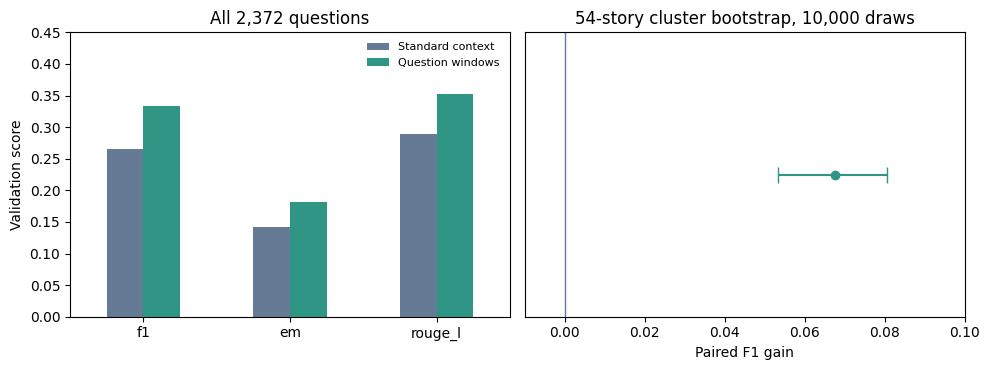

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
comparison[['Standard context', 'Question windows']].plot.bar(ax=axes[0], color=['#657a95', '#2f9585'], rot=0)
axes[0].set(ylabel='Validation score', ylim=(0, .45), title='All 2,372 questions')
axes[0].legend(frameon=False, fontsize=8)
ci = result['paired_story_f1_interval']
gain = comparison.loc['f1', 'Gain']
axes[1].errorbar([gain], [0], xerr=[[gain-ci['low']], [ci['high']-gain]], fmt='o', color='#2f9585', capsize=6)
axes[1].axvline(0, color='#657a95', linewidth=1)
axes[1].set(xlabel='Paired F1 gain', yticks=[], title='54-story cluster bootstrap, 10,000 draws')
axes[1].set_xlim(-.01, .10)
fig.tight_layout()
fig.savefig(root / 'assets/plots/full-context-validation.png', dpi=160)
plt.show()

In [3]:
coverage = pd.Series({'Validation questions': result['questions'], 'Validation stories': result['stories'], 'Bootstrap replicates': ci['resamples'], 'Test questions evaluated': result['test_questions_evaluated']}, name='Count')
display(coverage.to_frame())
print('Generator:', result['checkpoint'])
print('Weights SHA256:', result['generator_weights_sha256'])
print('Execution SHA256:', result['execution_sha256'])

,Count
Validation questions,2372
Validation stories,54
Bootstrap replicates,10000
Test questions evaluated,0


Generator: epoch-3
Weights SHA256: 4a51a48953e6c02c2c8aa5325a02600ae7a65dc8080abb5fb45e2b7131c39538
Execution SHA256: 43da51b0061bca4418a9f137fc4f9ed32706ccefc277ccdda04fff2d9a6a71d4


The F1 gain is 0.06763, with a descriptive paired story interval of [0.05334, 0.08059]. Validation has been reused across experiments, so this interval is not independent confirmation. A valid source span also does not prove that an answer follows from the citation. This notebook isolates context assembly. Notebook 05 contains the completed four-arm comparison with the trained reranker; notebook 06 reports the frozen held-out test.